# Project - Two networks, one vector

> This is the **solution** notebook; the task version is `seq2seq_dates_and_spaces.ipynb`.

The RNN chapter ended on a wall. In [54], an **encoder** read a whole sentence into one vector
$C$, and a **decoder** wrote the translation out of $C$ alone. The claim was that one fixed-size
vector cannot hold a long input, and that every output step gets the *same* $C$ even though each
step needs a *different* part of the input.

In this project you build that machine yourself and **measure** the claim, on two Armenian tasks:

| | input | output |
|---|---|---|
| **Task A - dates** | `սեպտեմբերի հինգ, երկու հազար քսանվեց թ.` | `2026-09-05` |
| **Task B - spaces** | `եսայսամենիննայումեմլուռ` | `ես այս ամենին նայում եմ լուռ` |

Both are **delayed** sequence-to-sequence problems ([53]'s taxonomy, the 4th picture): read
everything first, then write. The output has a different length from the input, and for dates
even a different order.

**What you will find out**

1. An encoder-decoder learns dates almost perfectly - and still cannot write a year it never saw.
2. On Task B it writes short sentences well, and then hits the wall: the longer the input, the
   more it forgets. A bigger $C$ moves the wall; it does not remove it.
3. A model with **no single $C$** - a per-letter tagger - has no wall at all. That is the idea
   attention generalises, in the LLM chapter.

## How to run this notebook

- **Use Google Colab with a GPU:** *Runtime > Change runtime type > T4 GPU*. The whole notebook
  then runs in about **11 minutes**. On a laptop CPU the same training takes hours (measured:
  one Task B model, 12 s on a T4, more than 6 minutes on a laptop).
- **Run the cells in order.** Each part builds on the previous one.
- **Cells with a comment like `# ~2 min on a T4`** on their first line are the slow ones. All the
  others take a second or two.
- **`# YOUR CODE HERE`** marks what you write (task version). Right after each one, a cell with
  `assert`s checks your code on a small known example and prints what it tested. If an assert
  fails, the message says what was expected.
- **Questions in bold** ask you to predict or explain. Write your answer in a markdown cell
  before you run the next cell - predicting first is the point.

**The parts**

| Part | What happens | Time on a T4 |
|---|---|---|
| 0 | Setup | ~20 s |
| 1 | Dates as data (the generator is given) | seconds |
| 2 | Characters to tensors | seconds |
| 3 | The encoder | seconds |
| 4 | The decoder and teacher forcing | seconds |
| 5 | Train on dates, then look at the mistakes | ~1 min |
| 6 | Same code, new task: spaces | seconds |
| 7 | The wall, measured (3 sizes of $C$) | ~7 min |
| 8 | Where it breaks | seconds |
| 9 | The right tool: a tagger | ~30 s |
| Bonus | Do not reverse the input; a one-directional tagger | ~2.5 min |

## Part 0 - Setup

One package is not on Colab by default: `rapidfuzz`, a fast **edit distance** (how many letters
you must insert, delete or change to turn one string into another). We use it to score Task B.

In [1]:
# ~20 s (installs one package)
%pip install -q rapidfuzz==3.14.6

The imports, the seed and the device. `SEED = 509` everywhere, so your numbers should be close to
the ones in the text (a GPU is not perfectly deterministic, so expect small differences in the
last digit).

In [2]:
import datetime as dt
import json
import random
import time
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from rapidfuzz.distance import Levenshtein
from torch.nn.utils.rnn import pack_padded_sequence
from tqdm import tqdm

SEED = 509
random.seed(SEED)
torch.manual_seed(SEED)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RED, BLUE, ORANGE, GREY = "#D90012", "#0033A0", "#F2A800", "#555555"
print("torch", torch.__version__, "| device:", DEV)
if DEV.type == "cpu":
    print("No GPU found. Runtime > Change runtime type > T4 GPU - on a CPU this notebook takes hours.")

torch 2.11.0+cu130 | device: cuda


---
## Part 1 - Dates as data 🧀

Neural networks need many examples. Nobody has a list of a hundred thousand Armenian dates
written in words, so we **generate** them. The generator below is given: read it, run it, and
make sure you believe its output before you train anything on it.

**Where the words come from.** The month names are from Unicode **CLDR**, the locale database
that phones and operating systems use to print dates. The number words start from CLDR's
Armenian spell-out rules, corrected where Wiktionary disagrees (90 is `իննսուն`, 10 is `տասը`,
hundreds are two words: `ինը հարյուր`). The instructor, a native speaker, looked over a sample of
the output.

**How a number becomes words.** Armenian builds numbers like a recipe:

- units: `մեկ, երկու, ..., ինը`; tens: `տասը, քսան, երեսուն, ...`
- 11-19 glue `տասն` to the unit: `տասնմեկ`, `տասներկու`
- 21-99 glue the ten to the unit, in one word: `քսան` + `վեց` = `քսանվեց`
- hundreds and thousands are separate words: `հազար ինը հարյուր իննսունինը` (1999),
  `երկու հազար քսանվեց` (2026)

In [3]:
MONTHS = ["հունվարի", "փետրվարի", "մարտի", "ապրիլի", "մայիսի", "հունիսի",          # "of January" ...
          "հուլիսի", "օգոստոսի", "սեպտեմբերի", "հոկտեմբերի", "նոյեմբերի", "դեկտեմբերի"]
MONTHS_SHORT = ["հնվ", "փտվ", "մրտ", "ապր", "մյս", "հնս", "հլս", "օգս", "սեպ", "հոկ", "նոյ", "դեկ"]
UNITS = ["", "մեկ", "երկու", "երեք", "չորս", "հինգ", "վեց", "յոթ", "ութ", "ինը"]
TENS = ["", "տասը", "քսան", "երեսուն", "քառասուն", "հիսուն", "վաթսուն", "յոթանասուն", "ութսուն", "իննսուն"]


def below_100(n):
    tens, unit = divmod(n, 10)
    if tens == 0:
        return UNITS[unit]
    if tens == 1:
        return "տասը" if unit == 0 else "տասն" + UNITS[unit]   # տասնմեկ, տասներկու, ...
    return TENS[tens] + UNITS[unit]                             # քսանվեց: one word


def year_in_words(y):
    thousands, rest = divmod(y, 1000)
    hundreds, rest = divmod(rest, 100)
    parts = ["հազար" if thousands == 1 else f"{UNITS[thousands]} հազար"]
    if hundreds:
        parts.append("հարյուր" if hundreds == 1 else f"{UNITS[hundreds]} հարյուր")
    if rest:
        parts.append(below_100(rest))
    return " ".join(parts)


FORM_NAMES = ["words", "digits + month", "short month", "all digits"]


def date_forms(d):
    '''The four ways people write the date d.'''
    return [f"{MONTHS[d.month - 1]} {below_100(d.day)}, {year_in_words(d.year)} թ.",
            f"{d.day} {MONTHS[d.month - 1]} {d.year}",
            f"{d.day} {MONTHS_SHORT[d.month - 1]} {d.year}",
            f"{d.day:02d}.{d.month:02d}.{d.year}"]


for form, text in zip(FORM_NAMES, date_forms(dt.date(2026, 9, 5))):
    print(f"{form:>15}:  {text}")

          words:  սեպտեմբերի հինգ, երկու հազար քսանվեց թ.
 digits + month:  5 սեպտեմբերի 2026
    short month:  5 սեպ 2026
     all digits:  05.09.2026


5 September 2026 - 05.09 - is our running example. Every form maps to the same answer,
`2026-09-05` (the **ISO** format: year, month, day). Notice what the network will have to do:

- **translate** words into digits (`երկու հազար քսանվեց` -> `2026`);
- **reorder**: every input starts with the day or the month, every output starts with the year.
  That is the alignment grid from [54] again - output step 1 needs the *end* of the input.

A few random dates, to see the variety:

In [4]:
rng = random.Random(SEED)
for _ in range(5):
    d = dt.date(1900, 1, 1) + dt.timedelta(rng.randrange(73049))
    print(d.isoformat(), " <- ", " | ".join(date_forms(d)))

2050-11-26  <-  նոյեմբերի քսանվեց, երկու հազար հիսուն թ. | 26 նոյեմբերի 2050 | 26 նոյ 2050 | 26.11.2050
1975-05-28  <-  մայիսի քսանութ, հազար ինը հարյուր յոթանասունհինգ թ. | 28 մայիսի 1975 | 28 մյս 1975 | 28.05.1975
1959-01-15  <-  հունվարի տասնհինգ, հազար ինը հարյուր հիսունինը թ. | 15 հունվարի 1959 | 15 հնվ 1959 | 15.01.1959
1948-02-24  <-  փետրվարի քսանչորս, հազար ինը հարյուր քառասունութ թ. | 24 փետրվարի 1948 | 24 փտվ 1948 | 24.02.1948
1944-10-23  <-  հոկտեմբերի քսաներեք, հազար ինը հարյուր քառասունչորս թ. | 23 հոկտեմբերի 1944 | 23 հոկ 1944 | 23.10.1944


**Small task (no code to check).** Write *your own birthday* in all four forms **by hand** in the
cell below, before running it. Then run it: it compares your spelling with the generator's. If
they differ, which one is right? (If the generator is wrong, tell your instructor - that is a
real bug report.)

In [5]:
my_birthday = dt.date(2001, 9, 5)                      # put yours here
my_forms = ["սեպտեմբերի հինգ, երկու հազար մեկ թ.",     # ... and write these by hand first
            "5 սեպտեմբերի 2001",
            "5 սեպ 2001",
            "05.09.2001"]
for name, mine, gen in zip(FORM_NAMES, my_forms, date_forms(my_birthday)):
    print(f"{'same' if mine == gen else 'DIFFERENT':>9}  {name:>15}:  you {mine!r}, generator {gen!r}")

     same            words:  you 'սեպտեմբերի հինգ, երկու հազար մեկ թ.', generator 'սեպտեմբերի հինգ, երկու հազար մեկ թ.'
     same   digits + month:  you '5 սեպտեմբերի 2001', generator '5 սեպտեմբերի 2001'
     same      short month:  you '5 սեպ 2001', generator '5 սեպ 2001'
     same       all digits:  you '05.09.2001', generator '05.09.2001'


### Three groups of dates

Every day from 1 January 1900 to 31 December 2099: 73,049 dates. We split them three ways:

- **2050s (held out):** every date from 2050 to 2059 is removed from training. The model will
  never see a year that starts with `205`. Can it still write one?
- **test:** 5,090 other dates, never trained on, from years the model *has* seen.
- **train:** everything else, about 64,000 dates. Each training example picks one of the four
  forms at random, so the model sees every date in many forms over training.

In [6]:
ALL_DATES = [dt.date(1900, 1, 1) + dt.timedelta(i) for i in range(73049)]
DECADE = [d for d in ALL_DATES if 2050 <= d.year <= 2059]
rest = [d for d in ALL_DATES if not 2050 <= d.year <= 2059]
random.Random(SEED).shuffle(rest)
TEST_DATES, TRAIN_DATES = rest[:5090], rest[5090:]

assert ALL_DATES[-1] == dt.date(2099, 12, 31)
assert len(DECADE) == 3652 and len(TEST_DATES) == 5090
assert not set(TEST_DATES) & set(TRAIN_DATES)
print(f"train {len(TRAIN_DATES):,} dates, test {len(TEST_DATES):,}, 2050s {len(DECADE):,}")

train 64,307 dates, test 5,090, 2050s 3,652


---
## Part 2 - Characters to tensors 🧀

A network reads numbers, not letters. We give every character an id: a **vocabulary**. Three ids
are special and come first:

| id | token | meaning |
|---|---|---|
| 0 | `<pad>` | filler, so that short sequences fit in a rectangle with long ones |
| 1 | `<sos>` | *start of sequence*: the decoder's first input, "start writing now" |
| 2 | `<eos>` | *end of sequence*: the decoder writes it to say "I am done" |

The input and the output get **separate** vocabularies: the encoder reads Armenian letters,
digits and punctuation; the decoder only ever writes the 11 characters `0-9` and `-`.

In [7]:
PAD, SOS, EOS = 0, 1, 2


class Vocab:
    '''Characters <-> ids. Ids 0, 1, 2 are <pad>, <sos>, <eos>.'''
    def __init__(self, chars):
        self.itos = ["<pad>", "<sos>", "<eos>"] + sorted(set(chars))
        self.stoi = {c: i for i, c in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)


date_in = Vocab("".join(f for d in ALL_DATES for f in date_forms(d)))
date_out = Vocab("0123456789-")
print(f"input vocabulary: {len(date_in)} ids, output vocabulary: {len(date_out)} ids")
print("".join(date_in.itos[3:]))

input vocabulary: 44 ids, output vocabulary: 14 ids
 ,.0123456789աբգդեզըթիլկհմյնոչպռսվտրցւփքօ


### A batch is a rectangle

We train on **batches**: many examples at once, stacked into one tensor of shape
`(batch, longest length)`. Shorter rows are filled with `<pad>` on the right. We also keep each
row's **true length**, because - remember [53] - pads are not neutral: an RNN that reads them
changes its state. The lengths let us tell the LSTM where every row really ends.

Write `encode_batch`: turn a list of strings into that padded tensor, optionally with `<eos>`
added to every row (the decoder's targets need it; the encoder's inputs do not).

In [8]:
def encode_batch(strings, vocab, add_eos=False):
    '''Strings -> (ids, lengths). ids: LongTensor (batch, longest) on DEV, padded with PAD on the
    right; lengths: LongTensor (batch,) on the CPU, counting the <eos> if add_eos.'''
    rows = [[vocab.stoi[c] for c in s] + ([EOS] if add_eos else []) for s in strings]
    longest = max(len(r) for r in rows)
    ids = torch.tensor([r + [PAD] * (longest - len(r)) for r in rows], device=DEV)
    return ids, torch.tensor([len(r) for r in rows])


def decode_ids(ids, vocab):
    '''The reverse, for reading outputs: stop at <eos>, skip <pad> and <sos>.'''
    out = []
    for row in ids.tolist():
        chars = []
        for i in row:
            if i == EOS:
                break
            if i > EOS:
                chars.append(vocab.itos[i])
        out.append("".join(chars))
    return out

**Check.** Three dates of different lengths, encoded and decoded again:

In [9]:
demo = ["05.09.2026", "5 սեպ 2026", "5 սեպտեմբերի 2026"]
x, lengths = encode_batch(demo, date_in)
y, y_len = encode_batch(["2026-09-05"] * 3, date_out, add_eos=True)
print("x:", tuple(x.shape), " lengths:", lengths.tolist())
print(x.cpu())
assert x.shape == (3, 17) and lengths.tolist() == [10, 10, 17], "shape or lengths are off"
assert (x[0, 10:] == PAD).all() and (x[2] != PAD).all(), "pads belong on the right, only after the text"
assert y[0].tolist()[-1] == EOS and y_len.tolist() == [11, 11, 11], "add_eos must append <eos> and count it"
assert decode_ids(x, date_in) == demo and decode_ids(y, date_out) == ["2026-09-05"] * 3
print("encode_batch: shapes, padding, <eos> and the round trip are right")

x: (3, 17)  lengths: [10, 10, 17]
tensor([[ 6, 11,  5,  6, 15,  5,  8,  6,  8, 12,  0,  0,  0,  0,  0,  0,  0],
        [11,  3, 35, 20, 33,  3,  8,  6,  8, 12,  0,  0,  0,  0,  0,  0,  0],
        [11,  3, 35, 20, 33, 37, 20, 28, 17, 20, 38, 24,  3,  8,  6,  8, 12]])
encode_batch: shapes, padding, <eos> and the round trip are right


Look at the printed tensor: the two short dates end in a run of zeros - the pads. Row 3 is the
longest and has none. That rectangle is what the GPU actually processes.

---
## Part 3 - The encoder 🧀🧀

This is [54]'s picture, now for real. The encoder reads the input one character at a time; its
**last state** is $C$, the *context vector*. Everything the decoder will ever know about the
input has to fit in there.

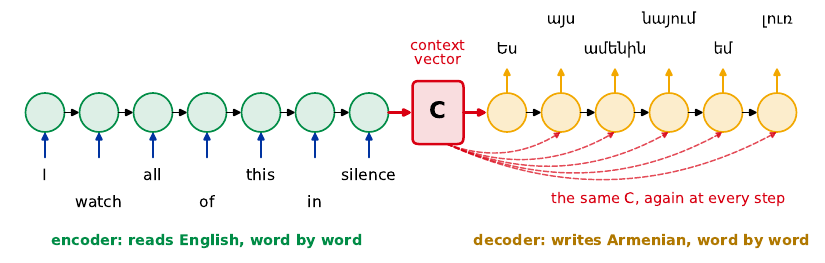

*[54]'s figure, for translation. Our decoder uses $C$ only as its **starting state** (Sutskever
et al., 2014). The dashed arrows - $C$ fed in again at every step - are Cho et al.'s (2014)
variant; we do not build it.*

**What exactly is $C$?** An LSTM carries two vectors ([54]): the hidden state $z$ and the cell
state $c$. After the last character, both are handed to the decoder as its initial state. So
$C = (z, c)$, each of size `hidden`. With `hidden = 128` that is 256 numbers - for a 40-letter
date, or for a 60-letter sentence.

**Packing.** `pack_padded_sequence` tells the LSTM each row's true length, so it stops at the
last real character and never reads the pads. It is PyTorch's version of [53]'s **mask**.
Without it, $C$ would be the state after reading several `<pad>`s - a different $C$ for the same
date depending on what else is in the batch.

The whole model in one class. Write `encode`: embed the characters, pack them, run the encoder
LSTM, and return its final `(z, c)`. The decoder parts are written for you; Part 4 explains them.

In [10]:
class Seq2Seq(nn.Module):
    def __init__(self, n_in, n_out, hidden, emb=32):
        super().__init__()
        self.enc_emb = nn.Embedding(n_in, emb, padding_idx=PAD)    # character id -> vector
        self.encoder = nn.LSTM(emb, hidden, batch_first=True)
        self.dec_emb = nn.Embedding(n_out, emb, padding_idx=PAD)
        self.decoder = nn.LSTM(emb, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_out)                      # decoder state -> a score per output character

    def encode(self, x, lengths):
        '''Read the whole input. Returns C = (z, c), each of shape (1, batch, hidden).'''
        packed = pack_padded_sequence(self.enc_emb(x), lengths, batch_first=True, enforce_sorted=False)
        _, C = self.encoder(packed)
        return C

    def forward(self, x, lengths, y_in):
        '''Teacher forcing (Part 4): start the decoder from C and feed it y_in, all steps at once.'''
        out, _ = self.decoder(self.dec_emb(y_in), self.encode(x, lengths))
        return self.head(out)                                     # (batch, steps, n_out)

**Check.** An untrained model, three dates. $C$ must have the right shape, and - because of
packing - a date's $C$ must not depend on what else is in the batch.

In [11]:
torch.manual_seed(SEED)
model = Seq2Seq(len(date_in), len(date_out), hidden=128).to(DEV)
z, c = model.encode(*encode_batch(demo, date_in))
print("z:", tuple(z.shape), " c:", tuple(c.shape))
z_alone, _ = model.encode(*encode_batch(demo[:1], date_in))
assert z.shape == c.shape == (1, 3, 128), "C should be (1, batch, hidden) twice"
assert torch.allclose(z[:, :1], z_alone, atol=1e-5), "C changed with the batch - are the pads read? (pack the input)"
print("first 6 numbers of C's z for", repr(demo[0]), ":", [round(v, 3) for v in z[0, 0, :6].tolist()])
print("encode: right shape, and C ignores the pads")

z: (1, 3, 128)  c: (1, 3, 128)
first 6 numbers of C's z for '05.09.2026' : [0.137, -0.02, 0.025, 0.057, -0.155, 0.026]
encode: right shape, and C ignores the pads


**Question.** The 10-character `05.09.2026` and a 40-character date in words both become exactly
256 numbers. What could go wrong as inputs get longer? Keep your answer - Part 7 measures it.

---
## Part 4 - The decoder and teacher forcing 🧀🧀

The decoder writes one character per step. At each step it takes **one character in** and gives
**a score for every possible next character** out. What goes in depends on whether we are
training or using the model.

### Training: teacher forcing

During training we know the right answer, so at every step we feed the decoder the **true**
previous character - not its own guess. That is **teacher forcing**: like a teacher who corrects
you after every word instead of letting one mistake derail the rest of the sentence. Its big
advantage: since every input is known in advance, all steps run in **one** LSTM call.

The decoder's input is the target **shifted right by one**, with `<sos>` in front:

| step | 1 | 2 | 3 | 4 | 5 | 6 | ... | 10 | 11 |
|---|---|---|---|---|---|---|---|---|---|
| decoder input | `<sos>` | 2 | 0 | 2 | 6 | - | ... | 0 | 5 |
| target (what it must predict) | 2 | 0 | 2 | 6 | - | 0 | ... | 5 | `<eos>` |

At step $t$ the decoder sees the target up to $t-1$ and must predict character $t$.

> **Common bugs here**
> - **Off by one:** feeding the target itself (not shifted) lets the decoder copy the answer it is
>   supposed to predict. The loss drops to almost zero in training, and the model writes garbage at
>   test time.
> - **Forgetting the pads in the loss:** after `<eos>` the targets are `<pad>`. Those positions must
>   not count, or the model learns to predict pads. `cross_entropy(..., ignore_index=PAD)` skips them.

Write `make_decoder_input`. One detail: after shifting, a shorter row has its `<eos>` sitting
inside the *input* (it was the last target). Replace it with `<pad>` - the step after `<eos>`
has a `<pad>` target, which the loss ignores anyway.

In [12]:
def make_decoder_input(y):
    '''y: targets (batch, T), each row ending in <eos> then <pad>s. Returns <sos> + y shifted right
    by one (the last column dropped), with any <eos> in the result replaced by <pad>.'''
    sos = torch.full((y.shape[0], 1), SOS, device=y.device)
    y_in = torch.cat([sos, y[:, :-1]], dim=1)
    y_in[y_in == EOS] = PAD
    return y_in

In [13]:
y, _ = encode_batch(["2026-09-05", "1900-01-01"], date_out, add_eos=True)
y_in = make_decoder_input(y)
print("target:       ", y[0].tolist())
print("decoder input:", y_in[0].tolist())
assert y_in.shape == y.shape, "the input must have the same length as the target"
assert y_in[0, 0] == SOS and (y_in[:, 1:] == y[:, :-1].masked_fill(y[:, :-1] == EOS, PAD)).all()
print("make_decoder_input: shifted right by one, <sos> first")

target:        [6, 4, 6, 10, 3, 4, 13, 3, 4, 9, 2]
decoder input: [1, 6, 4, 6, 10, 3, 4, 13, 3, 4, 9]
make_decoder_input: shifted right by one, <sos> first


### Inference: greedy decoding

At test time there is no answer to feed in. The decoder starts from $C$ and `<sos>`, picks its
**best guess** (the highest score), and feeds that guess back in as the next input - the same
write-and-feed-back loop as the ch11 name inventor, but always taking the top choice
(**greedy**) instead of sampling. It stops after `max_len` steps; everything after the first
`<eos>` is ignored when we read the result.

Training and inference now differ: in training the decoder always saw correct inputs; at test
time one wrong guess becomes the next input. Small errors can snowball - keep that in mind when
you read Task B's mistakes.

Write `greedy_decode`. Use the model's parts directly: `model.encode`, `model.dec_emb`,
`model.decoder` (it takes and returns the state) and `model.head`.

In [14]:
@torch.no_grad()
def greedy_decode(model, x, lengths, max_len):
    '''Start from C and <sos>; at every step feed back the decoder's own best guess.
    Returns the chosen ids, shape (batch, max_len).'''
    model.eval()
    state = model.encode(x, lengths)
    token = torch.full((x.shape[0], 1), SOS, device=x.device)
    out = []
    for _ in range(max_len):
        o, state = model.decoder(model.dec_emb(token), state)
        token = model.head(o).argmax(dim=-1)                       # (batch, 1): the best guess
        out.append(token)
    model.train()
    return torch.cat(out, dim=1)


def predict(model, strings, vin, vout, max_len, batch=256):
    '''Greedy outputs as strings, in batches.'''
    out = []
    for i in range(0, len(strings), batch):
        x, lengths = encode_batch(strings[i:i + batch], vin)
        out += decode_ids(greedy_decode(model, x, lengths, max_len), vout)
    return out

In [15]:
pred = greedy_decode(model, *encode_batch(demo, date_in), max_len=11)
assert pred.shape == (3, 11), "one id per step, max_len steps"
assert len(set(pred[0].tolist()) - set(range(len(date_out)))) == 0
print("untrained model writes:", predict(model, demo, date_in, date_out, 11))
print("greedy_decode: right shape (the untrained output is nonsense - that is expected)")

untrained model writes: ['', '', '']
greedy_decode: right shape (the untrained output is nonsense - that is expected)


---
## Part 5 - Train on dates 🧀🧀

The training loop is given. Each step:

1. draws a batch of 128 random (date, form) pairs from the training dates;
2. runs the encoder and the teacher-forced decoder;
3. computes the cross-entropy between the decoder's scores and the true next characters,
   ignoring pads;
4. takes one Adam step. `clip_grad_norm_` caps the gradient's size: the exploding half of
   [53]'s disease, handled the standard way.

**Hyperparameters.** `hidden = 128` (so $C$ has $2 \times 128$ numbers), embeddings of size 32,
learning rate `3e-3`, 3,000 steps. These were picked by trying a few on a T4: 600 steps already
reach ~100% on test dates, 3,000 make sure.

In [16]:
def train_seq2seq(sample_pair, vin, vout, hidden, steps, batch=64, lr=3e-3, label="training"):
    '''Train a fresh Seq2Seq. sample_pair() returns one (input string, output string).'''
    torch.manual_seed(SEED)
    model = Seq2Seq(len(vin), len(vout), hidden).to(DEV)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    losses, t0 = [], time.perf_counter()
    for step in tqdm(range(steps), desc=label, mininterval=10):
        xs, ys = zip(*[sample_pair() for _ in range(batch)])
        x, lengths = encode_batch(xs, vin)
        y, _ = encode_batch(ys, vout, add_eos=True)
        logits = model(x, lengths, make_decoder_input(y))
        loss = F.cross_entropy(logits.transpose(1, 2), y, ignore_index=PAD)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        losses.append(loss.item())
    last = losses[-100:]
    print(f"{label}: {steps} steps in {time.perf_counter() - t0:.0f} s, final loss {sum(last) / len(last):.3f}")
    return model, losses

**Predict first.** The model will see dates in all four forms. Which form do you expect it to get
wrong most often on the test dates - and on the 2050s, which it has never seen?

In [17]:
# ~30 s on a T4
rng = random.Random(SEED)


def date_pair():
    '''One training example: a random training date, in one of its four forms at random.'''
    d = rng.choice(TRAIN_DATES)
    return date_forms(d)[rng.randrange(4)], d.isoformat()


date_model, date_losses = train_seq2seq(date_pair, date_in, date_out, hidden=128, steps=3000,
                                        batch=128, label="dates")

dates:   0%|          | 0/3000 [00:00<?, ?it/s]

dates:  32%|███▏      | 957/3000 [00:10<00:21, 95.63it/s]

dates:  65%|██████▌   | 1956/3000 [00:20<00:10, 98.12it/s]

dates:  99%|█████████▉| 2972/3000 [00:30<00:00, 99.70it/s]

dates: 100%|██████████| 3000/3000 [00:30<00:00, 99.07it/s]

dates: 3000 steps in 30 s, final loss 0.000


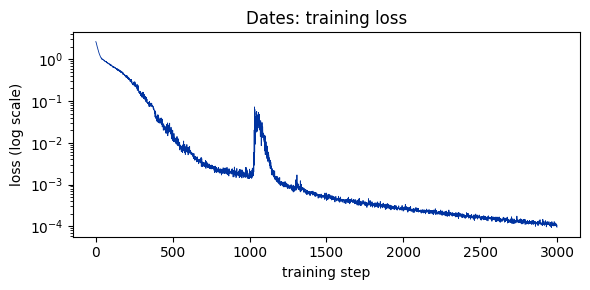

In [18]:
plt.figure(figsize=(6, 3))
plt.plot(date_losses, color=BLUE, lw=0.6)
plt.yscale("log"); plt.xlabel("training step"); plt.ylabel("loss (log scale)")
plt.title("Dates: training loss"); plt.tight_layout(); plt.show()

The loss falls by four orders of magnitude. The spike around step 1,000 is a brief instability -
one update knocks the model off course, and it recovers within about a hundred steps. Spikes like
this are common with long training; gradient clipping keeps them from blowing up.

Now the exam: every test date in all four forms, then every date of the 2050s in all four forms.
`exact` means the whole output is right - a date with one wrong digit is a wrong date.

In [19]:
def date_report(dates, name):
    rows = []
    for form in range(4):
        inputs = [date_forms(d)[form] for d in dates]
        truth = [d.isoformat() for d in dates]
        pred = predict(date_model, inputs, date_in, date_out, max_len=11)
        rows.append([p == t for p, t in zip(pred, truth)])
        print(f"{name:>6} | {FORM_NAMES[form]:>15}: {sum(rows[-1]) / len(dates):6.1%} exact")
    return rows


test_ok = date_report(TEST_DATES, "test")
decade_ok = date_report(DECADE, "2050s")

  test |           words: 100.0% exact


  test |  digits + month: 100.0% exact
  test |     short month: 100.0% exact


  test |      all digits: 100.0% exact
 2050s |           words:  33.9% exact


 2050s |  digits + month:  86.2% exact
 2050s |     short month:  82.8% exact


 2050s |      all digits:  77.6% exact


**Read the result.** On the test dates the model is perfect, 100% in every form - it has seen
every year, every month and every day before, just never in that combination. On the 2050s it
drops: to 78-86% for the forms with digits, and to 34% for the dates written in words. Let us
look at *how* it fails:

In [20]:
words = [date_forms(d)[0] for d in DECADE]
pred = predict(date_model, words, date_in, date_out, max_len=11)
wrong = [(w, d.isoformat(), p) for w, d, p in zip(words, DECADE, pred) if p != d.isoformat()]
for w, t, p in wrong[:6]:
    print(f"{w:<45} truth {t}   model {p}")
years = {}
for _, t, p in wrong:
    years[p[:4]] = years.get(p[:4], 0) + 1
print("\nmost common years it wrote instead:", sorted(years.items(), key=lambda kv: -kv[1])[:5])

հունվարի տասը, երկու հազար հիսուն թ.          truth 2050-01-10   model 2005-01-10
հունվարի տասնմեկ, երկու հազար հիսուն թ.       truth 2050-01-11   model 2005-01-11
հունվարի տասներեք, երկու հազար հիսուն թ.      truth 2050-01-13   model 2005-01-13
հունվարի տասնվեց, երկու հազար հիսուն թ.       truth 2050-01-16   model 2005-01-16
հունվարի տասնյոթ, երկու հազար հիսուն թ.       truth 2050-01-17   model 2005-01-17
հունվարի տասնութ, երկու հազար հիսուն թ.       truth 2050-01-18   model 2005-01-18

most common years it wrote instead: [('2035', 376), ('2095', 365), ('2075', 364), ('2015', 310), ('2065', 304)]


**Read the result.** `երկու հազար հիսուն` is 2050, but the model writes **2005**. The word
`հիսուն` (fifty) is not new to it - the 1950s are in training (`հազար ինը հարյուր հիսուն...`) -
but it never once came after `երկու հազար`. After `երկու հազար` the model has only seen the
2000s, 2010s, 2020s and so on, and it falls back to a year it knows. It learned the years it
saw, not the rule for building them.

**Question.** Look at the most common wrong years printed above. What do they have in common?
Compare the words `հիսուն` (fifty) and `հինգ` (five) - what might the model be reacting to?

**Question.** Why does the all-digits form `05.09.2052` fail too, even though the answer is
just the same digits, reordered? (Hint: when did the decoder ever write `5` right after `20`?)

This is the first lesson of the project: **a network interpolates between its examples; it does
not reliably extrapolate beyond them**, however perfect its test score looks.

---
## Part 6 - Same code, new task: spaces 🧀🧀

Task B: take Armenian text, remove the spaces, and ask the encoder-decoder to write it back
**with** the spaces. The decoder has to rebuild the whole sentence - every letter - from $C$
alone. That makes it a clean test of [54]'s bottleneck: the input grows, $C$ does not.

The text is from Armenian Wikipedia: 4,509 cleaned sentences (lowercase, Armenian letters only),
from 178 articles. The **test** sentences come from articles the model never trains on - among
them a few chosen for being funny (khash, mulberry vodka, donkeys...).

In [21]:
DATA_URL = ("https://raw.githubusercontent.com/HaykTarkhanyan/python_math_ml_course/main/"
            "ml/13_rnns/data/hy_sentences.tsv")
for path in [Path("data/hy_sentences.tsv"), Path("hy_sentences.tsv")]:
    if path.exists():
        break
else:
    path = Path("hy_sentences.tsv")
    with urlopen(Request(DATA_URL, headers={"User-Agent": "seq2seq-project"}), timeout=60) as r:
        path.write_bytes(r.read())
rows = [line.rstrip("\n").split("\t") for line in path.open(encoding="utf-8")]
articles = {}
for split, article, sentence in rows:
    articles.setdefault((split, int(article)), []).append(sentence)
TRAIN_ARTICLES = [" ".join(s).split() for (sp, _), s in articles.items() if sp == "train"]
TEST_ARTICLES = [" ".join(s).split() for (sp, _), s in articles.items() if sp == "test"]
TEST_SENTENCES = {s for sp, _, s in rows if sp == "test"}
assert len(rows) == 4509, f"expected 4509 sentences, got {len(rows)}"
print(f"{len(rows):,} sentences: {len(TRAIN_ARTICLES)} training articles, {len(TEST_ARTICLES)} test articles")

4,509 sentences: 147 training articles, 31 test articles


**Chunks of a chosen length.** To measure how length matters we need control over it, so we do
not use whole sentences. `make_chunk` picks a target length $L$ between 5 and 60 letters, a random
article and a random starting word, and takes whole words until there are at least $L$ letters.
It returns the pair (letters without spaces, the same with spaces).

In [22]:
LO, HI = 5, 60


def make_chunk(article_words, rng, lo=LO, hi=HI):
    target = rng.randint(lo, hi)
    while True:
        words = rng.choice(article_words)
        i, taken, n = rng.randrange(len(words)), [], 0
        while i < len(words) and n < target:
            taken.append(words[i]); n += len(words[i]); i += 1
        if target <= n <= hi + 8:
            spaced = " ".join(taken)
            return spaced.replace(" ", ""), spaced


rng = random.Random(SEED)
for _ in range(4):
    print("%-40s -> %s" % make_chunk(TRAIN_ARTICLES, rng))

թագավորությանըմիանալուցհետոայնդարձելէարագոնիթագավորության -> թագավորությանը միանալուց հետո այն դարձել է արագոնի թագավորության
կարիքչունենորովհետև                      -> կարիք չունեն որովհետև
միջոցչկասակայնկարողենտարբերաջակցողմիջոցներ -> միջոց չկա սակայն կարող են տարբեր աջակցող միջոցներ
կրոնըթեևդիմումիձևումպահանջվումէայստեղեկությունը -> կրոնը թեև դիմումի ձևում պահանջվում է այս տեղեկությունը


### One trick: read the input backwards

The encoder reads the letters **in reverse order**. Sutskever, Vinyals and Le (2014) found this
made their translation model much easier to train, and it does the same here (try the Bonus to see
how much). The reason: the decoder writes the *first* letters first. If the encoder read them
first too, they would be the oldest thing in $C$ - 60 steps back. Reversed, the first letters to
write are the **last** ones read, still fresh. The task does not change at all; only the reading
order does.

In [23]:
space_vocab = Vocab("".join(" ".join(s) for s in articles.values()))
print(f"vocabulary: {len(space_vocab)} ids:", "".join(space_vocab.itos[3:]))

TEST_CHUNKS = [make_chunk(TEST_ARTICLES, random.Random(SEED + k)) for k in range(1400)]
FUNNY = ["կաշվից պատրաստել են թմբուկ և տրեխ",
         "ի սկզբանե եղել է աղքատների սնունդ",
         "խաշը ուտում են մինչև նախաճաշը կամ նրա փոխարեն",
         "այդ գործընթացը կրկնվում է վայրկյանում չորս անգամ",
         "թթի օղու բուժիչ հատկությունների մասին գրում է զորի բալայանը",
         "խաշն ավանդաբար ուտում են վաղ առավոտյան առատ կերուխումի հաջորդ օրը"]
assert all(s in TEST_SENTENCES for s in FUNNY), "a display sentence is missing from the test split"
for s in FUNNY:
    print(f"{len(s.replace(' ', '')):>3} letters: {s}")

vocabulary: 43 ids:  աբգդեզէըթժիլխծկհձղճմյնշոչպջռսվտրցւփքօֆև
 28 letters: կաշվից պատրաստել են թմբուկ և տրեխ
 28 letters: ի սկզբանե եղել է աղքատների սնունդ
 38 letters: խաշը ուտում են մինչև նախաճաշը կամ նրա փոխարեն
 42 letters: այդ գործընթացը կրկնվում է վայրկյանում չորս անգամ
 51 letters: թթի օղու բուժիչ հատկությունների մասին գրում է զորի բալայանը
 56 letters: խաշն ավանդաբար ուտում են վաղ առավոտյան առատ կերուխումի հաջորդ օրը


The six display sentences, in English: donkey skin was made into drums and peasant shoes;
khash was originally poor people's food; khash is eaten before breakfast or instead of it; a cat
laps water four times a second; Zori Balayan writes about the healing powers of mulberry vodka;
khash is traditionally eaten early in the morning after a night of heavy feasting.

---
## Part 7 - The wall, measured 🧀🧀🧀

The experiment: train the **same** encoder-decoder with three sizes of $C$ - `hidden` = 64, 128
and 256 - each for 12,000 steps on chunks of 5 to 60 letters. Then score each one on the 1,400 test
chunks, grouped by length.

**Why 12,000 steps?** A curve that rises with length could just mean "long inputs are harder to
learn and we stopped too early" - not a wall at all. We checked before writing this (chunks of
5-30 letters, `hidden = 256`): training four times longer, 3,000 -> 12,000 steps, lowered the
error on the longest chunks only from 0.38 to 0.32, while the shortest stayed at 0.04. The
curves flatten out by 12,000 steps; the rise with length stays. What is left is mostly the limit
of the architecture, not of our patience.

**How we score.** Exact match is too harsh for a 60-letter sentence (one slip and it counts as
zero), so the main number is the **character error rate** (CER): the edit distance between the
output and the truth, divided by the truth's length. 0 is perfect; 0.5 means half the characters
would need fixing.

Write `cer`.

In [24]:
def cer(pred, truth):
    '''Character error rate: Levenshtein edit distance / len(truth).'''
    return Levenshtein.distance(pred, truth) / len(truth)

In [25]:
assert cer("ես այս", "ես այս") == 0
assert cer("եսայս", "ես այս") == 1 / 6, "one missing space in 6 characters"
assert cer("", "abc") == 1
print("cer: right on three known cases")

cer: right on three known cases


**Predict first.** Sketch three curves: CER (y) against input length (x), one per size of $C$.
Does each curve rise with length? Do bigger sizes rise later, rise slower, or not at all?

In [26]:
def score_by_length(pred, chunks, width=5):
    '''Mean CER, exact-match rate and letters-kept rate per length bucket (letters, not counting spaces).'''
    buckets = {}
    for p, (letters, spaced) in zip(pred, chunks):
        b = min(len(letters) // width * width, 65)
        d = buckets.setdefault(b, {"n": 0, "cer": 0.0, "exact": 0, "letters_ok": 0})
        d["n"] += 1
        d["cer"] += cer(p, spaced)
        d["exact"] += p == spaced
        d["letters_ok"] += p.replace(" ", "") == letters
    return {b: {"n": d["n"], "cer": d["cer"] / d["n"], "exact": d["exact"] / d["n"],
                "letters_ok": d["letters_ok"] / d["n"]} for b, d in sorted(buckets.items())}


def predict_spaces(model, chunks_or_texts, reverse=True):
    texts = [c[0] if isinstance(c, tuple) else c.replace(" ", "") for c in chunks_or_texts]
    out = []
    for i in range(0, len(texts), 200):
        part = texts[i:i + 200]
        out += predict(model, [t[::-1] if reverse else t for t in part], space_vocab, space_vocab,
                       max_len=int(1.4 * max(map(len, part))) + 5)
    return out


def train_spaces(hidden, steps=12000, reverse=True, label=None):
    rng = random.Random(SEED)
    def sample():
        letters, spaced = make_chunk(TRAIN_ARTICLES, rng)
        return (letters[::-1] if reverse else letters), spaced
    return train_seq2seq(sample, space_vocab, space_vocab, hidden, steps,
                         label=label or f"spaces, hidden {hidden}")

In [27]:
# ~7 min on a T4 (three models, ~2 min each)
space_models, wall = {}, {}
for hidden in (64, 128, 256):
    space_models[hidden], _ = train_spaces(hidden)
    wall[hidden] = score_by_length(predict_spaces(space_models[hidden], TEST_CHUNKS), TEST_CHUNKS)

spaces, hidden 64:   0%|          | 0/12000 [00:00<?, ?it/s]

spaces, hidden 64:   8%|▊         | 923/12000 [00:10<02:00, 92.20it/s]

spaces, hidden 64:  15%|█▌        | 1856/12000 [00:20<01:49, 92.82it/s]

spaces, hidden 64:  23%|██▎       | 2797/12000 [00:30<01:38, 93.37it/s]

spaces, hidden 64:  31%|███       | 3738/12000 [00:40<01:28, 93.38it/s]

...

spaces, hidden 256:  82%|████████▏ | 9864/12000 [02:10<00:28, 75.55it/s]

spaces, hidden 256:  89%|████████▊ | 10630/12000 [02:20<00:18, 75.85it/s]

spaces, hidden 256:  95%|█████████▍| 11396/12000 [02:30<00:07, 75.83it/s]

spaces, hidden 256: 100%|██████████| 12000/12000 [02:38<00:00, 75.70it/s]

spaces, hidden 256: 12000 steps in 159 s, final loss 0.157


In [28]:
def wall_table(results):
    keys = list(results)
    print("letters  " + "".join(f"{str(k):>14}" for k in keys))
    for b in results[keys[0]]:
        print(f"{b:>3}-{b + 4:<4} " + "".join(f"{results[k][b]['cer']:>14.2f}" for k in keys))


wall_table({f"C={h}": wall[h] for h in wall})

letters            C=64         C=128         C=256
  5-9              0.22          0.08          0.06
 10-14             0.34          0.16          0.11
 15-19             0.51          0.26          0.17
 20-24             0.56          0.37          0.26
 25-29             0.63          0.44          0.31
 30-34             0.63          0.49          0.38
 35-39             0.67          0.57          0.45
 40-44             0.67          0.60          0.50
 45-49             0.71          0.64          0.55
 50-54             0.71          0.66          0.57
 55-59             0.71          0.66          0.59
 60-64             0.73          0.67          0.62
 65-69             0.72          0.69          0.62


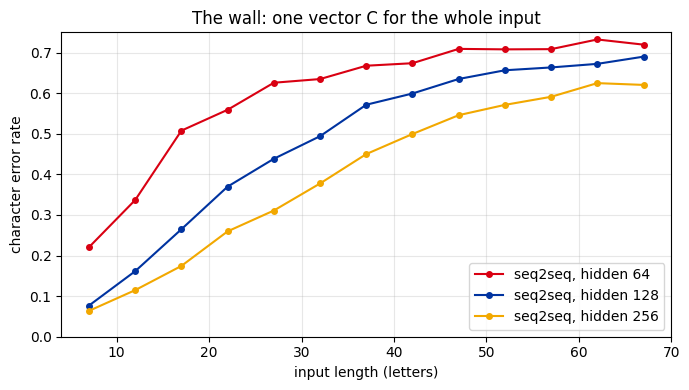

In [29]:
def plot_wall(curves, title):
    plt.figure(figsize=(7, 4))
    for (label, res), color in zip(curves.items(), [RED, BLUE, ORANGE, GREY, "black"]):
        xs = [b + 2 for b in res]
        plt.plot(xs, [res[b]["cer"] for b in res], "o-", color=color, label=label, ms=4)
    plt.xlabel("input length (letters)"); plt.ylabel("character error rate")
    plt.ylim(0, 0.75); plt.grid(alpha=0.3); plt.legend(); plt.title(title)
    plt.tight_layout(); plt.show()


plot_wall({f"seq2seq, hidden {h}": wall[h] for h in wall}, "The wall: one vector C for the whole input")

**Read the result.** Every curve rises. With `hidden = 256`, chunks of 5-9 letters come out with a
character error rate of 0.06; chunks of 60+ letters, 0.62 - most of the sentence is wrong. A
bigger $C$ helps - the `hidden = 256` curve sits below the other two at every length - but it
rises too, and even the smallest model's short chunks (0.22) are not solved. Doubling $C$ moves
the wall further out; it does not remove it.

That is [54]'s claim, measured: **the input grows, $C$ does not.** No fixed size is big enough for
every input, and the decoder has nothing to go back to - it must write the whole sentence from
what was squeezed in.

**Question.** If you doubled `hidden` again, to 512, what would you expect? What would that cost
(think of the parameter count: the LSTM weight matrices grow with `hidden` squared)?

---
## Part 8 - Where it breaks 🧀🧀🧀

The CER says *how much* goes wrong. Two more measurements say *what* goes wrong:

1. **Letters kept:** remove the spaces from the output. If what is left equals the input, every
   error was a spacing error - the model kept the text and only misplaced spaces. If not, it lost
   or invented letters.
2. **Where the first mistake is,** as a fraction of the sentence: near 0 means it goes wrong at
   once, near 1 means it goes wrong only at the very end.

Write `first_error`.

In [30]:
def first_error(pred, truth):
    '''Index of the first position where pred and truth differ, divided by len(truth);
    None if they are equal. A shorter pred that matches so far fails where it ends.'''
    if pred == truth:
        return None
    for i, (a, b) in enumerate(zip(pred, truth)):
        if a != b:
            return i / len(truth)
    return min(len(pred), len(truth)) / len(truth)

In [31]:
assert first_error("abc", "abc") is None
assert first_error("abx", "abcd") == 0.5
assert first_error("ab", "abcd") == 0.5, "ran out of letters at position 2 of 4"
print("first_error: right on three known cases")

first_error: right on three known cases


In [32]:
best = space_models[256]
pred = predict_spaces(best, TEST_CHUNKS)
groups = {"short (5-19 letters)": [], "long (40+ letters)": []}
for p, (letters, spaced) in zip(pred, TEST_CHUNKS):
    key = "short (5-19 letters)" if len(letters) < 20 else "long (40+ letters)" if len(letters) >= 40 else None
    if key:
        groups[key].append((p, letters, spaced))
for key, items in groups.items():
    kept = sum(p.replace(" ", "") == l for p, l, _ in items) / len(items)
    firsts = [f for p, _, s in items if (f := first_error(p, s)) is not None]
    print(f"{key:>22}: letters kept {kept:5.1%} | first mistake at {sum(firsts) / len(firsts):.0%} "
          f"of the sentence on average ({len(firsts)} of {len(items)} have one)")

  short (5-19 letters): letters kept 59.7% | first mistake at 45% of the sentence on average (140 of 313 have one)
    long (40+ letters): letters kept  0.7% | first mistake at 17% of the sentence on average (597 of 601 have one)


**Read the result.** On short chunks (5-19 letters) the model keeps every letter about 60% of the
time; when it errs, the first mistake comes about halfway through. On long chunks (40+) it keeps
the letters intact in under 1% of cases - it does not just misplace spaces, it **loses letters** -
and its first mistake comes much earlier, about a sixth of the way in.

Now the funny sentences. Read the outputs carefully: where does each one go wrong?

In [33]:
for s, p in zip(FUNNY, predict_spaces(best, FUNNY)):
    print(f"{len(s.replace(' ', '')):>3} letters")
    print(f"   truth: {s}\n   model: {p}\n")

 28 letters
   truth: կաշվից պատրաստել են թմբուկ և տրեխ
   model: կաշվից պատրաստել են կրթում և բետաք

 28 letters
   truth: ի սկզբանե եղել է աղքատների սնունդ
   model: իսկ զանակել երեք է աղեքնտրի լուսագը

 38 letters
   truth: խաշը ուտում են մինչև նախաճաշը կամ նրա փոխարեն
   model: խաշխուտումը նենի և մաշչանափակը մնջար բուսար

 42 letters
   truth: այդ գործընթացը կրկնվում է վայրկյանում չորս անգամ
   model: այդ գործընթացը կրկվածում է նվակցում նյուր բնավար

 51 letters
   truth: թթի օղու բուժիչ հատկությունների մասին գրում է զորի բալայանը
   model: թթի օրուսությա բուժող հին նեֆիլ մակուսի գրոսում նրանք ժաման

 56 letters
   truth: խաշն ավանդաբար ուտում են վաղ առավոտյան առատ կերուխումի հաջորդ օրը
   model: խաշխանավ դնազատում այն բերվա ռուտավորատատակեղջուն ուի համո ջերը



**Read the result.** Not one survives intact, not even the 28-letter ones. Most start with a
piece of the truth - `կաշվից պատրաստել են`, `այդ գործընթացը`, `թթի օ...` - and then the model
starts **inventing**: words that look and sound Armenian, with Armenian endings, but that are not
in the input (`կաշվից պատրաստել են կրթում և բետաք`). The decoder has learned what
Armenian looks like; what it has lost is *which* Armenian was in this particular sentence. That is
exactly what a bottleneck looks like from the inside: the general knowledge lives in the weights,
the specific sentence had to live in $C$, and $C$ ran out of room.

**Question.** Why does the model start right and go wrong later, and not the other way round?
(Hint: which letters did the encoder read last, and which does the decoder write first?)

**Wait - doesn't this contradict [54]?** [54] said the *early* words get overwritten, yet here
the model loses the *end* of the sentence. It is the same disease. What fades in $C$ is whatever
the encoder read **first** - and our encoder reads backwards, so what it read first is the end of
the sentence. Read forwards, the beginning would fade instead (and, as the Bonus shows, the model
learns far worse, because the first letters it must write are then the oldest thing in $C$).

---
## Part 9 - The right tool: a tagger 🧀🧀

Here is the honest part. Delayed seq2seq is **the wrong tool for Task B**, on purpose: it makes the
model rewrite letters it already had. Task B is really a **synced** problem ([53]'s 5th picture):
for every input letter, one yes/no answer - *is there a space after this letter?*

```
letters:  ե ս ա յ ս ա մ ե ն ի ն
tags:     0 1 0 0 1 0 0 0 0 0 0      ("ես այս ամենին")
```

A **tagger** reads the letters with a **bidirectional** LSTM ([53]) - forwards and backwards, so
at every letter it knows both what came before and what comes after - and outputs one tag per
letter. There is **no single $C$**: each tag comes from the LSTM state *at its own position*. And
it cannot lose letters: it only decides where the spaces go.

Write the two conversions.

In [34]:
def spaced_to_tags(spaced):
    '''"ես այս" -> [0, 1, 0, 0, 0]: 1 if a space follows that letter.'''
    tags = []
    for ch in spaced:
        if ch == " ":
            tags[-1] = 1
        else:
            tags.append(0)
    return tags


def tags_to_spaced(letters, tags):
    '''The reverse: put a space after every letter tagged 1 (never after the last letter).'''
    return "".join(ch + (" " if t == 1 and i < len(letters) - 1 else "") for i, (ch, t) in enumerate(zip(letters, tags)))

In [35]:
assert spaced_to_tags("ես այս") == [0, 1, 0, 0, 0]
assert tags_to_spaced("եսայս", [0, 1, 0, 0, 0]) == "ես այս"
assert tags_to_spaced("ես", [0, 1]) == "ես", "no trailing space after the last letter"
for _, spaced in TEST_CHUNKS[:50]:
    assert tags_to_spaced(spaced.replace(" ", ""), spaced_to_tags(spaced)) == spaced
print("spaced_to_tags and tags_to_spaced: they undo each other on 50 test chunks")

spaced_to_tags and tags_to_spaced: they undo each other on 50 test chunks


In [36]:
class Tagger(nn.Module):
    def __init__(self, n_in, hidden=64, emb=32, bidirectional=True):
        super().__init__()
        self.emb = nn.Embedding(n_in, emb, padding_idx=PAD)
        self.rnn = nn.LSTM(emb, hidden, batch_first=True, bidirectional=bidirectional)
        self.head = nn.Linear(hidden * (2 if bidirectional else 1), 2)    # 2 classes: space or not

    def forward(self, x):
        out, _ = self.rnn(self.emb(x))
        return self.head(out)                                             # (batch, letters, 2)


def train_tagger(steps=3000, bidirectional=True, batch=64, label="tagger"):
    torch.manual_seed(SEED)
    rng = random.Random(SEED)
    model = Tagger(len(space_vocab), bidirectional=bidirectional).to(DEV)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    t0 = time.perf_counter()
    for _ in tqdm(range(steps), desc=label, mininterval=10):
        pairs = [make_chunk(TRAIN_ARTICLES, rng) for _ in range(batch)]
        x, _ = encode_batch([l for l, _ in pairs], space_vocab)
        tags = torch.full(x.shape, -100, dtype=torch.long)                # -100 = ignored (the pads)
        for i, (_, spaced) in enumerate(pairs):
            t = spaced_to_tags(spaced)
            tags[i, :len(t)] = torch.tensor(t)
        loss = F.cross_entropy(model(x).transpose(1, 2), tags.to(DEV), ignore_index=-100)
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"{label}: {steps} steps in {time.perf_counter() - t0:.0f} s")
    return model


@torch.no_grad()
def predict_tagger(model, texts):
    model.eval()
    out = []
    for t in texts:
        letters = t[0] if isinstance(t, tuple) else t.replace(" ", "")
        x, _ = encode_batch([letters], space_vocab)
        out.append(tags_to_spaced(letters, model(x).argmax(-1)[0].tolist()))
    model.train()
    return out

In [37]:
# ~30 s on a T4
tagger = train_tagger()
wall["tagger"] = score_by_length(predict_tagger(tagger, TEST_CHUNKS), TEST_CHUNKS)
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"parameters: tagger {n_params(tagger):,} vs seq2seq hidden 256 {n_params(space_models[256]):,}")
wall_table({"C=64": wall[64], "C=128": wall[128], "C=256": wall[256], "tagger": wall["tagger"]})

tagger:   0%|          | 0/3000 [00:00<?, ?it/s]

tagger:  52%|█████▏    | 1574/3000 [00:10<00:09, 157.32it/s]

tagger: 100%|██████████| 3000/3000 [00:19<00:00, 157.31it/s]

tagger: 3000 steps in 19 s


parameters: tagger 51,810 vs seq2seq hidden 256 607,723
letters            C=64         C=128         C=256        tagger
  5-9              0.22          0.08          0.06          0.01
 10-14             0.34          0.16          0.11          0.02
 15-19             0.51          0.26          0.17          0.02
 20-24             0.56          0.37          0.26          0.02
 25-29             0.63          0.44          0.31          0.01
 30-34             0.63          0.49          0.38          0.02
 35-39             0.67          0.57          0.45          0.03
 40-44             0.67          0.60          0.50          0.02
 45-49             0.71          0.64          0.55          0.02
 50-54             0.71          0.66          0.57          0.02
 55-59             0.71          0.66          0.59          0.02
 60-64             0.73          0.67          0.62          0.02
 65-69             0.72          0.69          0.62          0.02


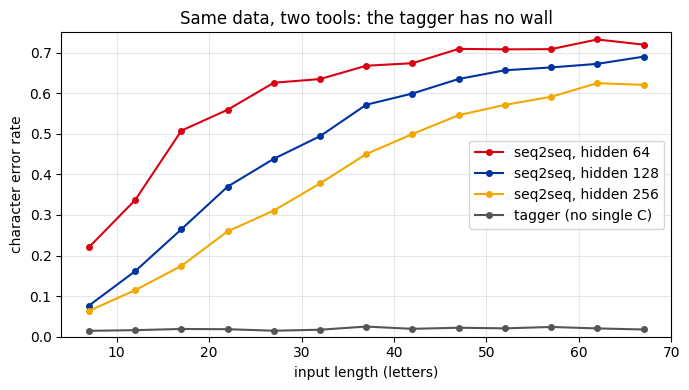

same կաշվից պատրաստել են թմբուկ և տրեխ
DIFF ի սկզբան ե եղել է աղքատների սնունդ
same խաշը ուտում են մինչև նախաճաշը կամ նրա փոխարեն
same այդ գործընթացը կրկնվում է վայրկյանում չորս անգամ
DIFF թթի օղուբուժիչ հատկությունների մասին գրում է զորիբալայանը
DIFF խաշն ավան դաբարուտում են վաղ առավոտ յան առատ կերուխումի հաջորդ օրը


In [38]:
plot_wall({"seq2seq, hidden 64": wall[64], "seq2seq, hidden 128": wall[128],
           "seq2seq, hidden 256": wall[256], "tagger (no single C)": wall["tagger"]},
          "Same data, two tools: the tagger has no wall")
for s, p in zip(FUNNY, predict_tagger(tagger, FUNNY)):
    print(("same " if p == s else "DIFF ") + p)

**Read the result.** The tagger's line is flat and close to zero at every length (0.01-0.03):
long inputs are no harder for it than short ones, and it has 12 times fewer parameters than the
`hidden = 256` seq2seq model. Its mistakes are of a different kind, too: a space in the wrong
place (`առավոտ յան`), never a lost or invented letter.
The difference is not the LSTM - both use one - but **where the answer comes from**. The seq2seq
decoder must find everything in $C$. The tagger reads its answer for letter $t$ from the state
*at letter $t$*.

That is the idea of **attention** (LLM-3), in its simplest form: instead of squeezing the input
into one vector, let every output step look at the part of the input it needs. Attention does it
without giving up delayed seq2seq - the output can still have a different length and order, as in
translation or our dates.

---
## Bonus 🎁 - two experiments 🧀🧀🧀

**1. Do not reverse the input.** Train `hidden = 128` exactly as in Part 7, but reading the letters
in their normal order. **Predict first:** how much worse will it be, and where - at the start of
the sentences or at the end?

In [39]:
# ~2 min on a T4
forward_model, _ = train_spaces(128, reverse=False, label="spaces, hidden 128, NOT reversed")
wall["128 not reversed"] = score_by_length(predict_spaces(forward_model, TEST_CHUNKS, reverse=False), TEST_CHUNKS)
wall_table({"C=128 reversed": wall[128], "C=128 not reversed": wall["128 not reversed"]})

spaces, hidden 128, NOT reversed:   0%|          | 0/12000 [00:00<?, ?it/s]

spaces, hidden 128, NOT reversed:   8%|▊         | 921/12000 [00:10<02:00, 92.03it/s]

spaces, hidden 128, NOT reversed:  15%|█▌        | 1859/12000 [00:20<01:48, 93.05it/s]

spaces, hidden 128, NOT reversed:  23%|██▎       | 2797/12000 [00:30<01:38, 93.28it/s]

spaces, hidden 128, NOT reversed:  31%|███       | 3733/12000 [00:40<01:29, 92.88it/s]

...

spaces, hidden 128, NOT reversed:  85%|████████▌ | 10258/12000 [01:50<00:18, 93.10it/s]

spaces, hidden 128, NOT reversed:  93%|█████████▎| 11196/12000 [02:00<00:08, 93.31it/s]

spaces, hidden 128, NOT reversed: 100%|██████████| 12000/12000 [02:09<00:00, 93.00it/s]

spaces, hidden 128, NOT reversed: 12000 steps in 129 s, final loss 0.943


letters  C=128 reversedC=128 not reversed
  5-9              0.08          0.44
 10-14             0.16          0.57
 15-19             0.26          0.68
 20-24             0.37          0.70
 25-29             0.44          0.72
 30-34             0.49          0.73
 35-39             0.57          0.76
 40-44             0.60          0.76
 45-49             0.64          0.75
 50-54             0.66          0.76
 55-59             0.66          0.77
 60-64             0.67          0.76
 65-69             0.69          0.78


**Read the result.** Reading forwards, even 5-9-letter chunks come out with a character error
rate of 0.44, against 0.08 reversed, and by 20 letters it is lost (0.70). Same model, same data,
same training; only the reading order changed.

**2. A one-directional tagger.** The tagger in Part 9 read the letters in both directions. With
only the forward direction it must decide "space after this letter?" without seeing the next
letters. How much does the right-hand context matter?

In [40]:
# ~25 s on a T4
uni = train_tagger(bidirectional=False, label="tagger, forward only")
wall["tagger forward only"] = score_by_length(predict_tagger(uni, TEST_CHUNKS), TEST_CHUNKS)
wall_table({"tagger, both ways": wall["tagger"], "tagger, forward only": wall["tagger forward only"]})

tagger, forward only:   0%|          | 0/3000 [00:00<?, ?it/s]

tagger, forward only:  60%|██████    | 1803/3000 [00:10<00:06, 180.24it/s]

tagger, forward only: 100%|██████████| 3000/3000 [00:16<00:00, 179.39it/s]

tagger, forward only: 3000 steps in 17 s


letters  tagger, both waystagger, forward only
  5-9              0.01          0.04
 10-14             0.02          0.04
 15-19             0.02          0.04
 20-24             0.02          0.05
 25-29             0.01          0.05
 30-34             0.02          0.05
 35-39             0.03          0.06
 40-44             0.02          0.06
 45-49             0.02          0.06
 50-54             0.02          0.06
 55-59             0.02          0.06
 60-64             0.02          0.06
 65-69             0.02          0.06


**Read the result.** Forward only, the error is about two to three times higher (0.04-0.06
against 0.01-0.03): to decide whether a word ends here, it helps to see how the next letters
begin. But the line is still flat - no single $C$, no wall.

**Going further (not run here).** Give the seq2seq model a **bidirectional encoder**: $C$ then has
both directions' final states, `2 * hidden` numbers (the decoder needs `hidden * 2` too, or a
linear layer to map down). Does it move the wall more than doubling `hidden` did?

---
## Wrap-up

| Claim | What you measured |
|---|---|
| an encoder-decoder can learn a delayed seq2seq task | dates: 100% on unseen dates, in all four forms |
| ... but a good test score is not understanding | the 2050s: "2050" comes out as "2005" - it interpolates, it does not extrapolate |
| one fixed vector $C$ cannot hold a long input ([54]) | Task B: the error rises with length for every size of $C$ |
| "so just make $C$ bigger?" ([54]) | a bigger $C$ moves the wall further out; none removes it |
| the bottleneck loses the *specific* input, not the language | long outputs start right, then invent Armenian-looking words |
| no single $C$, no wall | the bidirectional tagger stays flat at every length |

The last row is where the LLM chapter picks up: **attention** keeps the flexibility of delayed
seq2seq and gives every output step its own view of the input.

The curves are saved to `seq2seq_wall.json`, if you want to compare them with your own runs.

In [41]:
json.dump({str(k): v for k, v in wall.items()}, open("seq2seq_wall.json", "w", encoding="utf-8"), indent=1)
print("saved seq2seq_wall.json:", ", ".join(str(k) for k in wall))

saved seq2seq_wall.json: 64, 128, 256, tagger, 128 not reversed, tagger forward only
